# E219 · Does our benchmark require genuine semantic adaptation?

After BDD driving footage, each learner sees unlabeled crops of German traffic signs from real tracks. The task requires fine-grained sign identity, with a separate probe for speed-limit values. This changes both the semantic task and image scale. The archive predates frozen DINO, so its original pretraining exposure to these concepts is unknown. The fixed DINO readout measures initial transfer directly. [GTSRB dataset](https://benchmark.ini.rub.de/gtsrb_dataset.html)

A deterministic track split separates unlabeled support, linear-probe fit, and held-out test. Each physical sign track belongs to one split. The optimizer sees only support pixels. The two ordinary Late4 arms start from BDD +32 and +520 checkpoints with their optimizer states. The weaker arm retains DINO’s first eight blocks and patch embedding, resets the top four blocks, and settles fresh SimSiam heads for 32 BDD minibatches before seeing any signs. All adaptation arms train the same four blocks, use the same 256 sign minibatches per seed, and preserve sign orientation.

| Split | Track count | Images used |
| --- | --- | --- |
| support | 567 | 17010 |
| test | 151 | 302 |
| fit | 170 | 340 |

| Probe | Classes | Frozen DINO balanced accuracy |
| --- | --- | --- |
| sign_type | 38 | 45.08% |
| speed_limit | 7 | 65.24% |

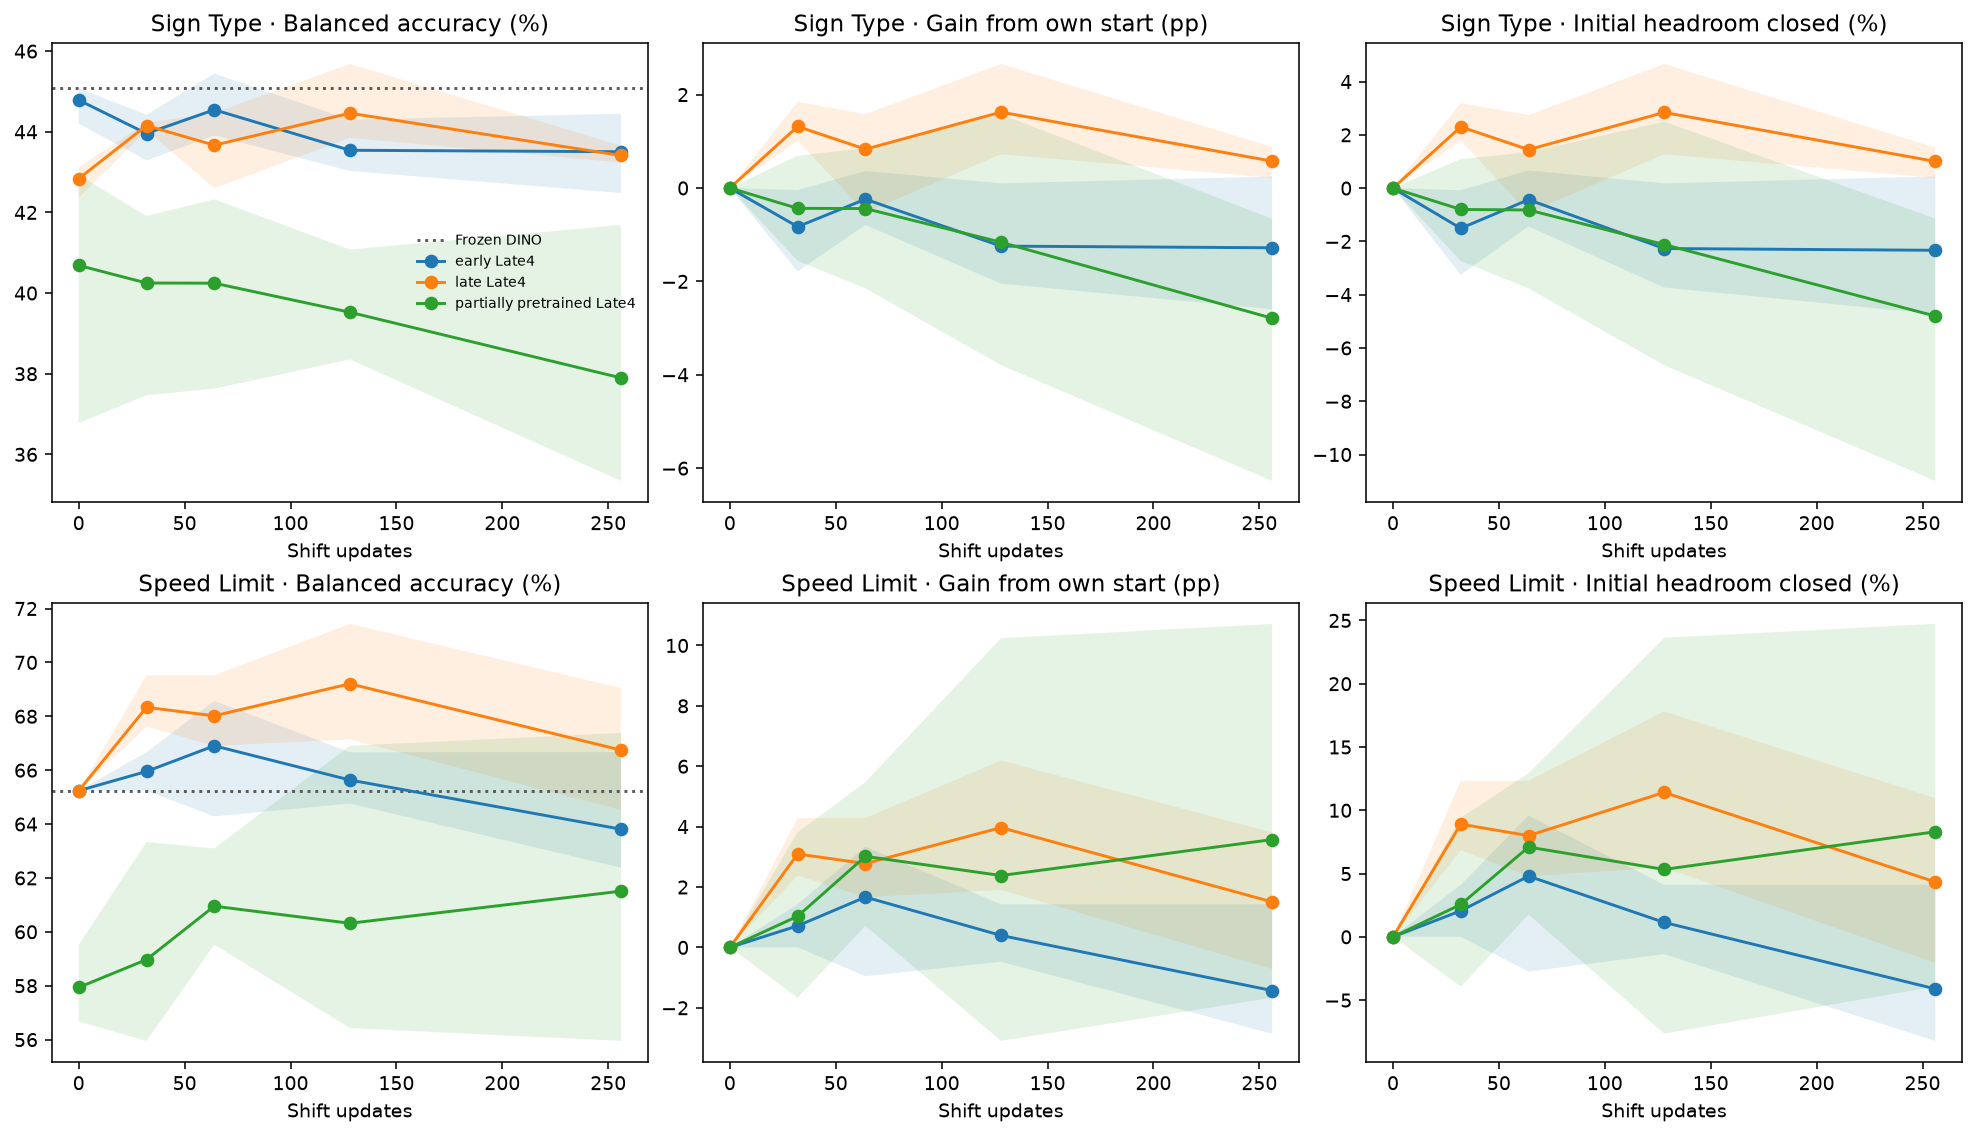

| Probe | Policy | Initial accuracy | Final accuracy | Paired gains (pp) |
| --- | --- | --- | --- | --- |
| sign_type | early Late4 | 44.79% | 43.51% | -1.49, +0.24, -2.60 |
| sign_type | late Late4 | 42.84% | 43.41% | +0.22, +0.88, +0.63 |
| sign_type | partially pretrained Late4 | 40.69% | 37.90% | -1.43, -6.27, -0.66 |
| speed_limit | early Late4 | 65.24% | 63.81% | -2.86, -2.86, +1.43 |
| speed_limit | late Late4 | 65.24% | 66.75% | -0.71, +1.43, +3.81 |
| speed_limit | partially pretrained Late4 | 57.94% | 61.51% | -1.67, +1.67, +10.71 |

| Probe | Early minus late gain by seed (pp) | Early minus late headroom closed (pp) |
| --- | --- | --- |
| sign_type | -1.71, -0.63, -3.22 | -3.10, -1.09, -5.83 |
| speed_limit | -2.14, -4.29, -2.38 | -6.16, -12.33, -6.85 |

## Historical BDD retention

| Seed | Policy | BDD probe mean at start | After 256 updates | Change (pp) |
| --- | --- | --- | --- | --- |
| 1 | early Late4 | 61.64% | 61.37% | -0.27 |
| 1 | late Late4 | 63.56% | 63.64% | +0.08 |
| 1 | partially pretrained Late4 | 63.02% | 63.47% | +0.45 |
| 2 | early Late4 | 61.81% | 62.22% | +0.41 |
| 2 | late Late4 | 63.00% | 62.97% | -0.03 |
| 2 | partially pretrained Late4 | 62.25% | 62.39% | +0.14 |
| 3 | early Late4 | 61.87% | 61.65% | -0.23 |
| 3 | late Late4 | 63.66% | 63.75% | +0.10 |
| 3 | partially pretrained Late4 | 63.07% | 62.68% | -0.39 |